**24BAD130 Vishal S DL Lab Exp-09 - TEXT CLASSIFICATION AND TEXT GENERATION USING TRANSFORMERS**

**Part A — Dataset preparation and preprocessing**

In [1]:
!pip install -q transformers datasets accelerate scikit-learn pandas matplotlib

In [2]:
# 24BAD130 Vishal S

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoModelForSeq2SeqLM,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("24BAD130 Vishal S ")
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

24BAD130 Vishal S 
PyTorch version: 2.11.0+cu130
GPU available: True


In [3]:
#Load the IMDb dataset

dataset = load_dataset("stanfordnlp/imdb")

print(dataset)
print("Training samples:", len(dataset["train"]))
print("Testing samples:", len(dataset["test"]))

print("\nSample review:")
print(dataset["train"][0]["text"][:500])
print("Label:", dataset["train"][0]["label"])

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
Training samples: 25000
Testing samples: 25000

Sample review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent
Label: 0


                                                text  label
0  I rented I AM CURIOUS-YELLOW from my video sto...      0
1  "I Am Curious: Yellow" is a risible and preten...      0
2  If only to avoid making this type of film in t...      0
3  This film was probably inspired by Godard's Ma...      0
4  Oh, brother...after hearing about this ridicul...      0

Dataset shape: (25000, 2)

Missing values:
 text     0
label    0
dtype: int64

Class distribution:
 label
0    12500
1    12500
Name: count, dtype: int64


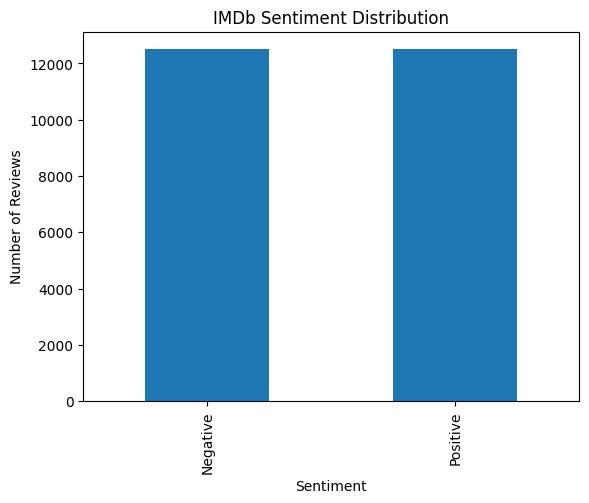

In [4]:
#Explore the dataset and class distribution

df = pd.DataFrame(dataset["train"][:])

print(df.head())
print("\nDataset shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nClass distribution:\n", df["label"].value_counts())

df["sentiment"] = df["label"].map({
    0: "Negative",
    1: "Positive"
})

df["sentiment"].value_counts().plot(
    kind="bar", title="IMDb Sentiment Distribution"
)
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [5]:
#Create smaller training and testing subsets

TRAIN_SIZE = 2000
TEST_SIZE = 1000

train_data = dataset["train"].shuffle(
    seed=SEED
).select(range(TRAIN_SIZE))

test_data = dataset["test"].shuffle(
    seed=SEED
).select(range(TEST_SIZE))

print("Selected training samples:", len(train_data))
print("Selected testing samples:", len(test_data))

Selected training samples: 2000
Selected testing samples: 1000


In [6]:
#Load the BERT tokenizer and tokenize the reviews

BERT_MODEL = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL)

def tokenize_reviews(examples):
    return bert_tokenizer(
        examples["text"],
        truncation=True,
        max_length=256
    )

tokenized_train = train_data.map(
    tokenize_reviews,
    batched=True
)

tokenized_test = test_data.map(
    tokenize_reviews,
    batched=True
)

tokenized_train = tokenized_train.rename_column("label", "labels")
tokenized_test = tokenized_test.rename_column("label", "labels")

print("Tokenization completed.")
print(tokenized_train[0].keys())
print("First review token IDs:")
print(tokenized_train[0]["input_ids"][:20])

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Tokenization completed.
dict_keys(['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'])
First review token IDs:
[101, 2045, 2003, 2053, 7189, 2012, 2035, 2090, 3481, 3771, 1998, 6337, 2099, 2021, 1996, 2755, 2008, 2119, 2024, 2610]


**Part B — Fine-tuning BERT for text classification**

In [7]:
#Prepare the datasets for batch processing

train_dataset = tokenized_train.select_columns(
    ["input_ids", "attention_mask", "labels"]
)

test_dataset = tokenized_test.select_columns(
    ["input_ids", "attention_mask", "labels"]
)

data_collator = DataCollatorWithPadding(
    tokenizer=bert_tokenizer
)

print("Training dataset ready:", len(train_dataset))
print("Testing dataset ready:", len(test_dataset))

Training dataset ready: 2000
Testing dataset ready: 1000


In [8]:
#Load the pretrained BERT model

bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL,
    num_labels=2,
    id2label={0: "Negative", 1: "Positive"},
    label2id={"Negative": 0, "Positive": 1}
)

print("Pretrained BERT model loaded successfully.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Pretrained BERT model loaded successfully.


In [9]:
#Define evaluation metrics and training parameters

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "f1": f1_score(
            labels, predictions, zero_division=0
        )
    }


training_args = TrainingArguments(
    output_dir="./bert_results",
    num_train_epochs=1,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=50,
    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=SEED
)

print("Training parameters configured.")

Training parameters configured.


In [10]:
#Fine-tune the BERT model

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    processing_class=bert_tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.302760,0.300948,0.873000,0.854617,0.891393,0.872618


TrainOutput(global_step=250, training_loss=0.43306143188476565, metrics={'train_runtime': 39.0254, 'train_samples_per_second': 51.249, 'train_steps_per_second': 6.406, 'total_flos': 262736944328160.0, 'train_loss': 0.43306143188476565, 'epoch': 1.0})

In [11]:
#Evaluate the model

results = trainer.evaluate()

print("BERT Evaluation Results")
print("-" * 30)

for metric, value in results.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.302760,0.300948,1,0.873000,0.854617,0.891393,0.872618


BERT Evaluation Results
------------------------------
eval_loss: 0.3009
eval_accuracy: 0.8730
eval_precision: 0.8546
eval_recall: 0.8914
eval_f1: 0.8726


              precision    recall  f1-score   support

    Negative       0.89      0.86      0.87       512
    Positive       0.85      0.89      0.87       488

    accuracy                           0.87      1000
   macro avg       0.87      0.87      0.87      1000
weighted avg       0.87      0.87      0.87      1000



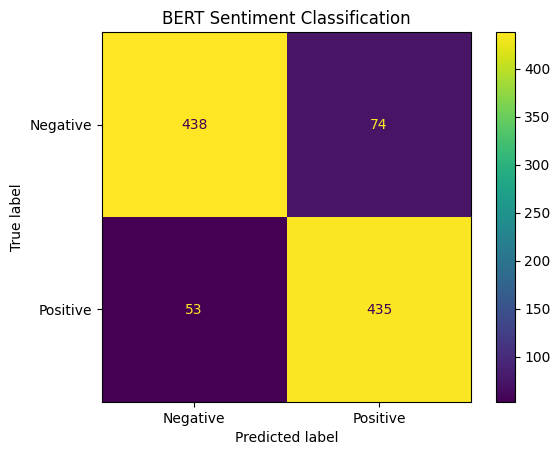

In [12]:
#Display the classification report and confusion matrix

pred_output = trainer.predict(test_dataset)

y_true = pred_output.label_ids
y_pred = np.argmax(pred_output.predictions, axis=-1)

print(classification_report(
    y_true,
    y_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot()
plt.title("BERT Sentiment Classification")
plt.show()

In [13]:
#Test BERT using new reviews

def predict_sentiment(review):
    inputs = bert_tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        max_length=256
    )

    device = next(bert_model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    bert_model.eval()

    with torch.no_grad():
        outputs = bert_model(**inputs)

    probabilities = torch.softmax(outputs.logits, dim=-1)[0]
    predicted_class = torch.argmax(probabilities).item()

    return {
        "Review": review,
        "Predicted Sentiment": bert_model.config.id2label[
            predicted_class
        ],
        "Confidence": round(probabilities[predicted_class].item(), 4)
    }


sample_reviews = [
    "This movie was fantastic and the acting was excellent.",
    "The movie was boring, poorly written and a complete disappointment."
]

for review in sample_reviews:
    print(predict_sentiment(review))
    print()

{'Review': 'This movie was fantastic and the acting was excellent.', 'Predicted Sentiment': 'Positive', 'Confidence': 0.9624}

{'Review': 'The movie was boring, poorly written and a complete disappointment.', 'Predicted Sentiment': 'Negative', 'Confidence': 0.9285}



In [14]:
#Save the fine-tuned model and tokenizer

MODEL_PATH = "./saved_bert_model"

trainer.save_model(MODEL_PATH)
bert_tokenizer.save_pretrained(MODEL_PATH)

print("BERT model and tokenizer saved to:", MODEL_PATH)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT model and tokenizer saved to: ./saved_bert_model


**Part C — Sequence-to-sequence text generation using Transformers**

In [15]:
#Load the pretrained text generation model

T5_MODEL = "google/flan-t5-small"

t5_tokenizer = AutoTokenizer.from_pretrained(T5_MODEL)

t5_model = AutoModelForSeq2SeqLM.from_pretrained(T5_MODEL)

t5_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

t5_model = t5_model.to(t5_device)
t5_model.eval()

print("FLAN-T5-small loaded successfully.")
print("Running on:", t5_device)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

FLAN-T5-small loaded successfully.
Running on: cuda


In [16]:
#Generate a summary from a movie review

review_text = """
The movie tells the story of a young musician who struggles to achieve
success. The acting is excellent, the music is beautiful, and the story
is emotional. Some scenes are slow, but the ending is satisfying.
"""

prompt = "Summarize this movie review in 2 sentences: " + review_text

inputs = t5_tokenizer(
    prompt,
    return_tensors="pt",
    truncation=True,
    max_length=512
).to(t5_device)

with torch.no_grad():
    output_ids = t5_model.generate(
        **inputs,
        max_new_tokens=60,
        num_beams=4,
        early_stopping=True
    )

generated_summary = t5_tokenizer.decode(
    output_ids[0],
    skip_special_tokens=True
)

print("INPUT REVIEW:")
print(review_text)

print("\nGENERATED SUMMARY:")
print(generated_summary)

INPUT REVIEW:

The movie tells the story of a young musician who struggles to achieve
success. The acting is excellent, the music is beautiful, and the story
is emotional. Some scenes are slow, but the ending is satisfying.


GENERATED SUMMARY:
The music is beautiful and the story is uplifting.


In [17]:
#Experiment with different generation settings

def generate_summary(text, beams=4, max_tokens=60):
    prompt = "Summarize this movie review: " + text

    inputs = t5_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(t5_device)

    with torch.no_grad():
        output_ids = t5_model.generate(
            **inputs,
            max_new_tokens=max_tokens,
            num_beams=beams,
            early_stopping=True
        )

    return t5_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )


review_1 = (
    "The actors delivered wonderful performances. "
    "The story was engaging and the music was memorable."
)

review_2 = (
    "The film had a weak story, poor acting and many boring scenes. "
    "I would not recommend watching it."
)

print("REVIEW 1 — Summary:")
print(generate_summary(review_1, beams=2, max_tokens=40))

print("\nREVIEW 2 — Summary:")
print(generate_summary(review_2, beams=4, max_tokens=60))

REVIEW 1 — Summary:
This movie is a must see for anyone who enjoys a movie.

REVIEW 2 — Summary:
This movie is a waste of time and money. It is a waste of time and money. It is a waste of time and money. It is a waste of time and money. It is a waste of time and money. It is a waste of time and money


In [18]:
#Save the generated outputs

generation_results = pd.DataFrame([
    {
        "Input Review": review_1,
        "Generated Summary": generate_summary(
            review_1, beams=2, max_tokens=40
        ),
        "Beam Size": 2
    },
    {
        "Input Review": review_2,
        "Generated Summary": generate_summary(
            review_2, beams=4, max_tokens=60
        ),
        "Beam Size": 4
    }
])

generation_results.to_csv(
    "generated_summaries.csv",
    index=False
)

print(generation_results)
print("\nGenerated outputs saved to generated_summaries.csv")

                                        Input Review  \
0  The actors delivered wonderful performances. T...   
1  The film had a weak story, poor acting and man...   

                                   Generated Summary  Beam Size  
0  This movie is a must see for anyone who enjoys...          2  
1  This movie is a waste of time and money. It is...          4  

Generated outputs saved to generated_summaries.csv


**Part D — Model testing and output analysis**

In [19]:
#Test positive and negative reviews using BERT

test_reviews = [
    "An amazing movie with excellent acting and a beautiful story.",
    "A terrible movie with poor acting and a boring storyline.",
    "I enjoyed every moment of this wonderful film.",
    "The film was disappointing and not worth watching."
]

classification_results = []

for review in test_reviews:
    result = predict_sentiment(review)
    classification_results.append(result)

    print("Review:", result["Review"])
    print("Predicted:", result["Predicted Sentiment"])
    print("Confidence:", result["Confidence"])
    print("-" * 50)

classification_df = pd.DataFrame(classification_results)
classification_df.to_csv(
    "classification_results.csv", index=False
)

Review: An amazing movie with excellent acting and a beautiful story.
Predicted: Positive
Confidence: 0.9631
--------------------------------------------------
Review: A terrible movie with poor acting and a boring storyline.
Predicted: Negative
Confidence: 0.9235
--------------------------------------------------
Review: I enjoyed every moment of this wonderful film.
Predicted: Positive
Confidence: 0.9496
--------------------------------------------------
Review: The film was disappointing and not worth watching.
Predicted: Negative
Confidence: 0.8908
--------------------------------------------------


In [20]:
#Compare text generation settings

comparison_review = """
The film has a compelling story, talented actors and impressive visuals.
However, the second half is slow and some scenes are unnecessary.
Overall, it provides an enjoyable experience.
"""

summary_2_beams = generate_summary(
    comparison_review, beams=2, max_tokens=40
)

summary_4_beams = generate_summary(
    comparison_review, beams=4, max_tokens=60
)

print("Original Review:")
print(comparison_review)

print("\nSummary with 2 beams:")
print(summary_2_beams)

print("\nSummary with 4 beams:")
print(summary_4_beams)

Original Review:

The film has a compelling story, talented actors and impressive visuals.
However, the second half is slow and some scenes are unnecessary.
Overall, it provides an enjoyable experience.


Summary with 2 beams:
This is a great film. It's a great film. It's a great film. It's a great film.

Summary with 4 beams:
This is a great movie. It's a great movie. It's a great movie. It's a great movie. It's a great movie.


In [21]:
#Compare BERT and T5 outputs

print("MODEL COMPARISON")
print("=" * 50)

print("\nBERT — Sentiment Classification")
for result in classification_results:
    print(
        result["Predicted Sentiment"],
        "| Confidence:",
        result["Confidence"]
    )

print("\nFLAN-T5 — Text Generation")
print("Original:", comparison_review)
print("Generated:", summary_4_beams)

comparison_df = pd.DataFrame([
    {
        "Model": "BERT",
        "Task": "Sentiment Classification",
        "Input": test_reviews[0],
        "Output": predict_sentiment(test_reviews[0])[
            "Predicted Sentiment"
        ]
    },
    {
        "Model": "FLAN-T5-small",
        "Task": "Text Summarization",
        "Input": comparison_review,
        "Output": summary_4_beams
    }
])

comparison_df.to_csv("model_comparison.csv", index=False)
print("\nComparison saved to model_comparison.csv")

MODEL COMPARISON

BERT — Sentiment Classification
Positive | Confidence: 0.9631
Negative | Confidence: 0.9235
Positive | Confidence: 0.9496
Negative | Confidence: 0.8908

FLAN-T5 — Text Generation
Original: 
The film has a compelling story, talented actors and impressive visuals.
However, the second half is slow and some scenes are unnecessary.
Overall, it provides an enjoyable experience.

Generated: This is a great movie. It's a great movie. It's a great movie. It's a great movie. It's a great movie.

Comparison saved to model_comparison.csv
